In [1]:
setwd("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/survival")

In [2]:
library(dplyr)
library(tidyr)
library(survival)
library(survminer)

# ---------------------------------------------------------------
# 1. Parse the R2 DataGrabber file
# ---------------------------------------------------------------
parse_r2_export <- function(path) {
  lines <- readLines(path)
  split_lines <- strsplit(lines, "\t")

  header <- split_lines[[1]]
  sample_ids <- header[-c(1, 2)]  # drop the two label columns

  rows <- split_lines[-1]

  # Build a named list: row name -> vector of values (length = n_samples)
  data_list <- list()
  for (row in rows) {
    if (length(row) < 2) next
    raw_name <- row[1]
    name <- sub("^#", "", raw_name)   # tracks start with '#', genes don't
    values <- row[-c(1, 2)]
    # pad/truncate defensively
    n <- min(length(values), length(sample_ids))
    values <- values[1:n]
    data_list[[name]] <- values
  }

  # Coerce to data.frame, one row per sample
  df <- as.data.frame(data_list, stringsAsFactors = FALSE)
  rownames(df) <- sample_ids[1:nrow(df)]
  df
}

path <- "ps_avgpres_gse85217geo763_hugene11t_box1788879227-datagrabber-.txt"
df <- parse_r2_export(path)

cat("Parsed", nrow(df), "samples x", ncol(df), "columns\n")
print(colnames(df))


to_numeric_na <- function(x) {
  x[x == "na"] <- NA
  as.numeric(x)
}

df$event    <- to_numeric_na(df$dead)
df$time     <- to_numeric_na(df$`os_.years.`)   # R replaces () with . in names sometimes; check actual name
df$ADAR     <- to_numeric_na(df$ADAR)
df$ADARB1   <- to_numeric_na(df$ADARB1)
df$ADARB2   <- to_numeric_na(df$ADARB2)
df$age      <- to_numeric_na(df$age)
df$subgroup <- ifelse(df$subgroup == "na", NA, df$subgroup)
df$gender   <- ifelse(df$gender == "na", NA, df$gender)

# NOTE: check the exact column name R gave the os_(years) column —
# R sanitizes special characters in data.frame column names.
# Run colnames(df) and look for something like "os_.years." or "os_..years.."

Warning message:
"package 'dplyr' was built under R version 4.4.3"



Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union


Warning message:
"package 'survival' was built under R version 4.4.3"
Warning message:
"package 'survminer' was built under R version 4.4.3"
Loading required package: ggplot2

Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Loading required package: ggpubr

Warning message:
"package 'ggpubr' was built under R version 4.4.3"

Attaching package: 'survminer'


The following object is masked from 'package:survival':

    myeloma




Parsed 763 samples x 18 columns
 [1] "age"                      "agegroup"                
 [3] "data.set"                 "dead"                    
 [5] "gender"                   "geo.gse85217"            
 [7] "histology"                "id"                      
 [9] "lab.id"                   "met_status_.1_met__0_m0."
[11] "os_.years."               "subgroup"                
[13] "subtype"                  "tissue"                  
[15] "type"                     "ADAR"                    
[17] "ADARB1"                   "ADARB2"                  


In [3]:
# Build survival object
clean <- df %>%
  filter(!is.na(time), !is.na(event), !is.na(ADAR), !is.na(subgroup), time > 0)

cat("Analysis-ready N:", nrow(clean), "\n")
table(clean$subgroup)

# ---- Analysis 1: ADAR within Group 3 only ----
g3 <- clean %>% filter(subgroup == "group3") %>%
  select(time, event, ADAR) %>% drop_na()

cat("Group 3 N =", nrow(g3), "\n")
fit_g3 <- coxph(Surv(time, event) ~ ADAR, data = g3)
summary(fit_g3)

# ---- Analysis 2: ADAR adjusted for subgroup (+ age, gender), full cohort ----
full <- clean %>%
  select(time, event, ADAR, subgroup, age, gender) %>%
  mutate(subgroup = relevel(factor(subgroup), ref = "group3")) %>%
  drop_na()

cat("Full-cohort model N =", nrow(full), "\n")
fit_full <- coxph(Surv(time, event) ~ ADAR + subgroup + age + gender, data = full)
summary(fit_full)

# Check proportional hazards assumption for ADAR term
cox.zph(fit_full)

Analysis-ready N: 610 



group3 group4    shh    wnt 
   112    263    172     63 

Group 3 N = 112 


Call:
coxph(formula = Surv(time, event) ~ ADAR, data = g3)

  n= 112, number of events= 46 

          coef exp(coef)  se(coef)     z Pr(>|z|)
ADAR 0.0003796 1.0003797 0.0009278 0.409    0.682

     exp(coef) exp(-coef) lower .95 upper .95
ADAR         1     0.9996    0.9986     1.002

Concordance= 0.479  (se = 0.048 )
Likelihood ratio test= 0.17  on 1 df,   p=0.7
Wald test            = 0.17  on 1 df,   p=0.7
Score (logrank) test = 0.17  on 1 df,   p=0.7


Full-cohort model N = 597 


Call:
coxph(formula = Surv(time, event) ~ ADAR + subgroup + age + gender, 
    data = full)

  n= 597, number of events= 156 

                     coef  exp(coef)   se(coef)      z Pr(>|z|)    
ADAR            0.0013918  1.0013928  0.0006586  2.113 0.034588 *  
subgroupgroup4 -0.2837930  0.7529225  0.2402908 -1.181 0.237587    
subgroupshh    -0.3583866  0.6988029  0.2741686 -1.307 0.191153    
subgroupwnt    -2.0658923  0.1267052  0.6099014 -3.387 0.000706 ***
age            -0.0085625  0.9914741  0.0095914 -0.893 0.372004    
genderm         0.0471775  1.0483081  0.1721432  0.274 0.784039    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

               exp(coef) exp(-coef) lower .95 upper .95
ADAR              1.0014     0.9986   1.00010    1.0027
subgroupgroup4    0.7529     1.3282   0.47013    1.2058
subgroupshh       0.6988     1.4310   0.40830    1.1960
subgroupwnt       0.1267     7.8923   0.03834    0.4187
age               0.9915     1.0086   0.97301    

           chisq df      p
ADAR      3.7475  1 0.0529
subgroup 14.8639  3 0.0019
age       5.3769  1 0.0204
gender    0.0196  1 0.8885
GLOBAL   21.8798  6 0.0013

In [14]:
# Build survival object
clean <- df %>%
  filter(!is.na(time), !is.na(event), !is.na(ADAR), !is.na(subgroup), time > 0)

cat("Analysis-ready N:", nrow(clean), "\n")
table(clean$subgroup)

# # ---- Analysis 1: ADAR within Group 3 only ----
# g3 <- clean %>% filter(subgroup == "group3") %>%
#   select(time, event, ADAR) %>% drop_na()

# cat("Group 3 N =", nrow(g3), "\n")
# fit_g3 <- coxph(Surv(time, event) ~ ADAR, data = g3)
# summary(fit_g3)

# ---- Analysis 2: ADAR adjusted for subgroup (+ age, gender), full cohort ----
full <- clean %>%
  select(time, event, ADAR, ADARB1, ADARB2, subgroup,age, gender) %>%
  mutate(subgroup = relevel(factor(subgroup), ref = "group3")) %>%
  drop_na()

cat("Full-cohort model N =", nrow(full), "\n")
fit_full <- coxph(Surv(time, event) ~ ADAR + ADARB1 +ADARB2 + subgroup+age+gender, data = full)
summary(fit_full)

# Check proportional hazards assumption for ADAR term
cox.zph(fit_full)
####################33
# Extract coefficients
results <- summary(fit_full)$coefficients

# Original p-values
p_values <- results[, "Pr(>|z|)"]

# Adjust p-values using FDR (Benjamini-Hochberg)
p_adj <- p.adjust(p_values, method = "BH")

# Combine results
results_adj <- data.frame(
  Variable = rownames(results),
  HR = results[, "exp(coef)"],
  CI_lower = exp(results[, "coef"] - 1.96 * results[, "se(coef)"]),
  CI_upper = exp(results[, "coef"] + 1.96 * results[, "se(coef)"]),
  P_value = p_values,
  P_adjusted = p_adj
)

results_adj


Analysis-ready N: 610 



group3 group4    shh    wnt 
   112    263    172     63 

Full-cohort model N = 597 


Call:
coxph(formula = Surv(time, event) ~ ADAR + ADARB1 + ADARB2 + 
    subgroup + age + gender, data = full)

  n= 597, number of events= 156 

                     coef  exp(coef)   se(coef)      z Pr(>|z|)    
ADAR            0.0017921  1.0017937  0.0006871  2.608 0.009106 ** 
ADARB1         -0.0010880  0.9989126  0.0004869 -2.234 0.025452 *  
ADARB2         -0.0013107  0.9986902  0.0006791 -1.930 0.053610 .  
subgroupgroup4 -0.3949929  0.6736849  0.2493749 -1.584 0.113209    
subgroupshh    -0.3550198  0.7011595  0.2766111 -1.283 0.199330    
subgroupwnt    -2.1313096  0.1186818  0.6178136 -3.450 0.000561 ***
age            -0.0148699  0.9852401  0.0101861 -1.460 0.144341    
genderm         0.0212465  1.0214738  0.1720135  0.124 0.901698    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

               exp(coef) exp(-coef) lower .95 upper .95
ADAR              1.0018     0.9982   1.00045    1.0031
ADARB1            0.9989     1.0011   0.99796    0.9999
ADARB2 

            chisq df      p
ADAR     3.21e+00  1 0.0732
ADARB1   1.58e+00  1 0.2081
ADARB2   1.84e+00  1 0.1750
subgroup 1.46e+01  3 0.0022
age      7.07e+00  1 0.0079
gender   6.23e-04  1 0.9801
GLOBAL   2.41e+01  8 0.0022

,Variable,HR,CI_lower,CI_upper,P_value,P_adjusted
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ADAR,ADAR,1.0017937,1.00044539,1.0031438,0.009105960,0.036423838
ADARB1,ADARB1,0.9989126,0.99795967,0.9998664,0.025452405,0.067873081
ADARB2,ADARB2,0.9986902,0.99736177,1.0000204,0.053610081,0.107220163
subgroupgroup4,subgroupgroup4,0.6736849,0.41322311,1.0983202,0.113209179,0.181134686
subgroupshh,subgroupshh,0.7011595,0.40771880,1.2057935,0.199330198,0.227805941
subgroupwnt,subgroupwnt,0.1186818,0.03535823,0.3983617,0.000561082,0.004488656
age,age,0.9852401,0.96576503,1.0051080,0.144341486,0.192455314
genderm,genderm,1.0214738,0.72913237,1.4310278,0.901698317,0.901698317


In [15]:
results_adj$Variable

[1] "ADAR"           "ADARB1"         "ADARB2"         "subgroupgroup4"
[5] "subgroupshh"    "subgroupwnt"    "age"            "genderm"

`height` was translated to `width`.
`height` was translated to `width`.
`height` was translated to `width`.


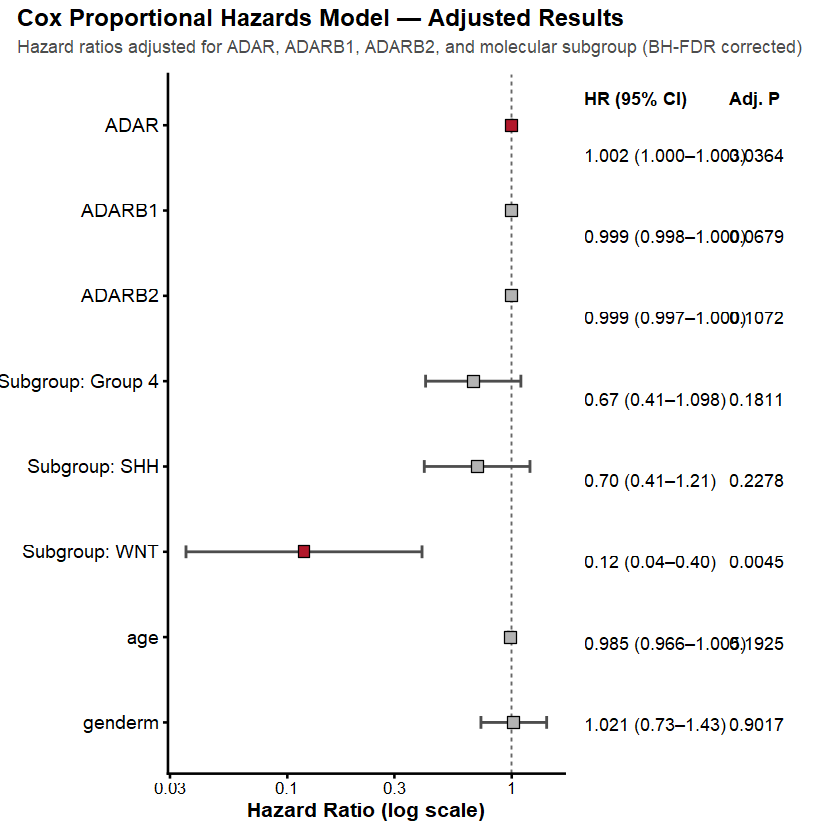

In [16]:
library(ggplot2)
library(dplyr)
library(patchwork)

# ---- Prepare data ----
results_adj <- results_adj %>%
  mutate(
    Variable = gsub("subgroup", "Subgroup: ", Variable),
    Variable = gsub("group4", "Group 4", Variable),
    Variable = gsub("shh", "SHH", Variable),
    Variable = gsub("wnt", "WNT", Variable),
    sig = P_adjusted < 0.05,
    HR_label  = ifelse(abs(HR - 1) < 0.1, sprintf("%.3f", HR), sprintf("%.2f", HR)),
    CI_label  = paste0("(", 
                        ifelse(abs(CI_lower - 1) < 0.1, sprintf("%.3f", CI_lower), sprintf("%.2f", CI_lower)),
                        "–",
                        ifelse(abs(CI_upper - 1) < 0.1, sprintf("%.3f", CI_upper), sprintf("%.2f", CI_upper)),
                        ")"),
    p_label   = format.pval(P_adjusted, digits = 2, eps = 0.001)
  )

# Order: keep continuous vars on top, subgroup below (or order by effect size — your call)
order_vars <- c("ADAR", "ADARB1", "ADARB2", "Subgroup: Group 4", "Subgroup: SHH", "Subgroup: WNT", "age", "genderm")
results_adj$Variable <- factor(results_adj$Variable, levels = rev(order_vars))
results_adj <- results_adj %>% arrange(Variable)

# ---- Left panel: forest plot ----
p_forest <- ggplot(results_adj, aes(x = HR, y = Variable)) +
  geom_vline(xintercept = 1, linetype = "dashed", color = "grey40", linewidth = 0.4) +
  geom_errorbarh(aes(xmin = CI_lower, xmax = CI_upper), height = 0.15, 
                  color = "grey30", linewidth = 0.6) +
  geom_point(aes(fill = sig), shape = 22, size = 3.5, color = "black", stroke = 0.4) +
  scale_fill_manual(values = c(`TRUE` = "#B2182B", `FALSE` = "grey70"), guide = "none") +
  scale_x_log10(breaks = c(0.03, 0.1, 0.3, 1, 3),
                labels = c("0.03", "0.1", "0.3", "1", "3")) +
  labs(x = "Hazard Ratio (log scale)", y = NULL) +
  theme_classic(base_size = 12, base_family = "serif") +
  theme(
    axis.text.y = element_text(color = "black", size = 11),
    axis.title.x = element_text(face = "bold"),
    plot.margin = margin(5, 5, 5, 5)
  )

# ---- Right panel: aligned text table (HR, CI, adj-p) ----
p_table <- ggplot(results_adj, aes(y = Variable)) +
  geom_text(aes(x = 0, label = paste0(HR_label, " ", CI_label)), hjust = 0, size = 3.6, family = "serif") +
  geom_text(aes(x = 1.6, label = p_label), hjust = 0, size = 3.6, family = "serif") +
  annotate("text", x = 0, y = length(order_vars) + 0.7, label = "HR (95% CI)", 
           hjust = 0, fontface = "bold", size = 3.7, family = "serif") +
  annotate("text", x = 1.6, y = length(order_vars) + 0.7, label = "Adj. P", 
           hjust = 0, fontface = "bold", size = 3.7, family = "serif") +
  xlim(0, 2.6) +
  expand_limits(y = length(order_vars) + 1) +
  theme_void()

# ---- Combine ----
final_plot <- p_forest + p_table + plot_layout(widths = c(2, 1.3)) +
  plot_annotation(
    title = "Cox Proportional Hazards Model — Adjusted Results",
    subtitle = "Hazard ratios adjusted for ADAR, ADARB1, ADARB2, and molecular subgroup (BH-FDR corrected)",
    theme = theme(
      plot.title = element_text(face = "bold", size = 14, family = "serif"),
      plot.subtitle = element_text(size = 10.5, family = "serif", color = "grey30")
    )
  )

final_plot

# ---- Save at publication resolution ----
ggsave("forest_plot.pdf", final_plot, width = 16, height = 5, units = "in")
ggsave("forest_plot.tiff", final_plot, width = 16, height = 5, units = "in", dpi = 300, compression = "lzw")

In [63]:
getwd()

[1] "H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/survival"

`height` was translated to `width`.


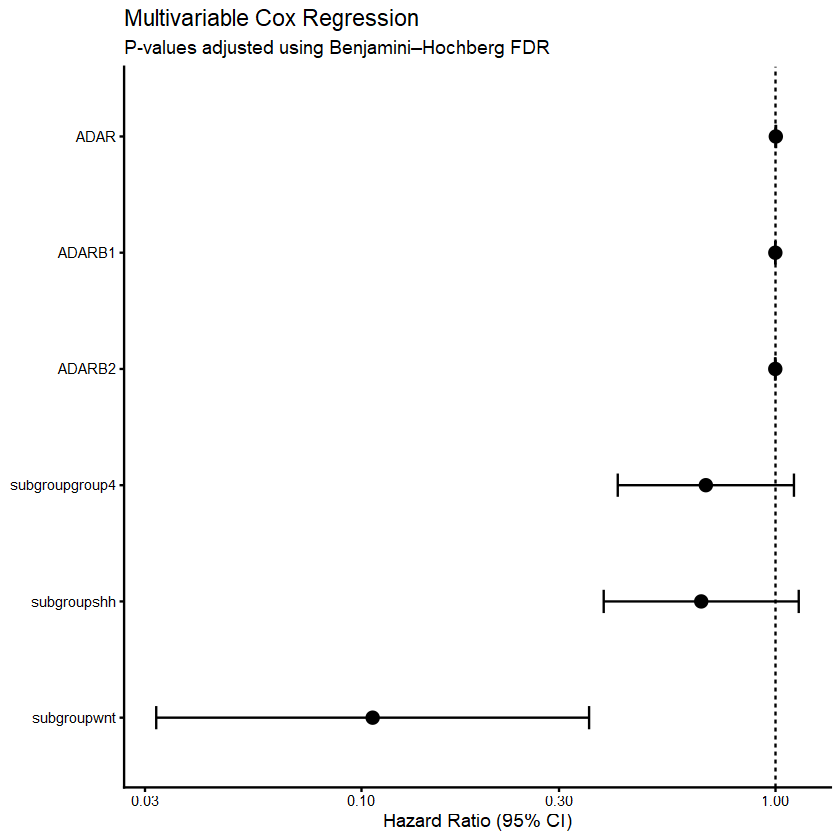

In [48]:
library(broom)
library(dplyr)
library(ggplot2)

# Extract Cox results
cox_results <- tidy(
  fit_full,
  exponentiate = TRUE,
  conf.int = TRUE
)

# Adjust p-values using BH/FDR
cox_results <- cox_results %>%
  mutate(
    p_adjusted = p.adjust(p.value, method = "BH")
  )

# Forest plot
ggplot(
  cox_results,
  aes(
    x = estimate,
    y = reorder(term, estimate)
  )
) +
  geom_vline(
    xintercept = 1,
    linetype = "dashed"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.2
  ) +
  geom_point(size = 3) +
  scale_x_log10() +
  labs(
    x = "Hazard Ratio (95% CI)",
    y = NULL,
    title = "Multivariable Cox Regression",
    subtitle = "P-values adjusted using Benjamini–Hochberg FDR"
  ) +
  theme_classic()

`height` was translated to `width`.


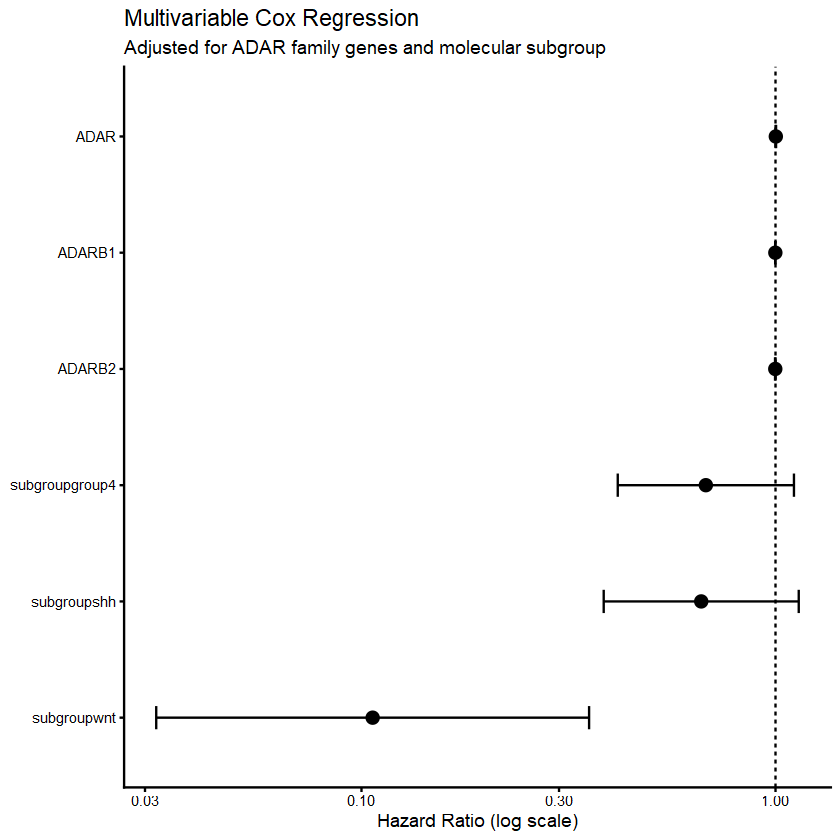

In [43]:
ggplot(cox_results, 
       aes(x = estimate, 
           y = reorder(term, estimate))) +
  
  geom_vline(xintercept = 1, 
             linetype = "dashed") +
  
  geom_errorbarh(
    aes(xmin = conf.low, xmax = conf.high),
    height = 0.2
  ) +
  
  geom_point(size = 3) +
  
  scale_x_log10() +
  
  labs(
    x = "Hazard Ratio (log scale)",
    y = NULL,
    title = "Multivariable Cox Regression",
    subtitle = "Adjusted for ADAR family genes and molecular subgroup"
  ) +
  
  theme_classic()

Raw log-rank p-value: 0.0006346193 
Bonferroni-adjusted p-value: 0.001903858 


Ignoring unknown labels:
• colour : "ADAR expression"
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's fill values."


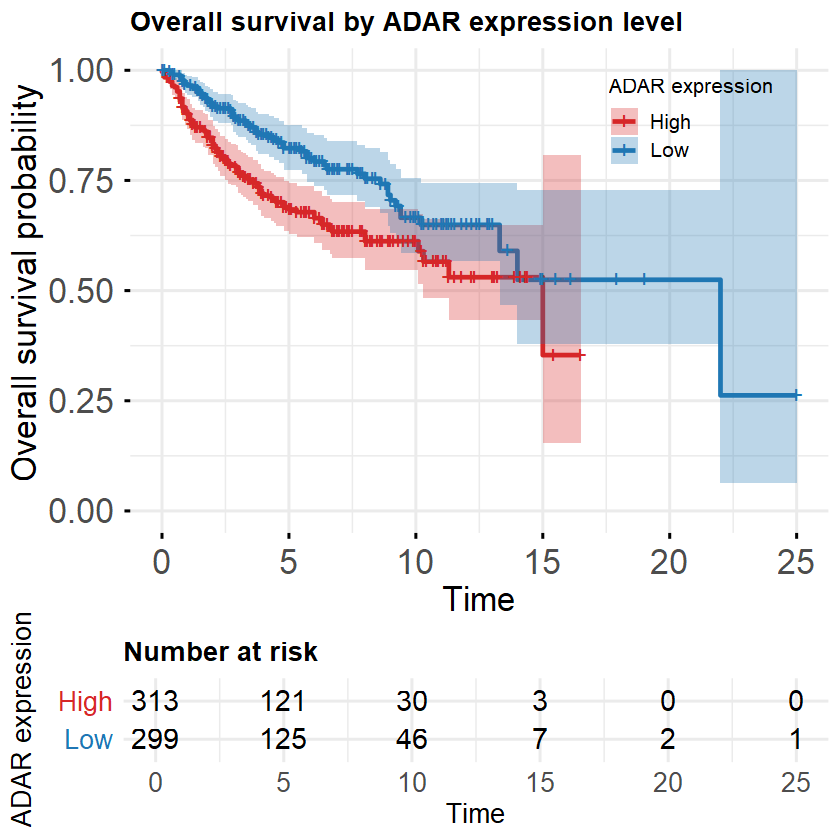

In [44]:
library(survival)
library(survminer)
library(dplyr)

# Median split on ADAR
df_km <- df %>%
  mutate(ADAR_group = ifelse(ADAR > median(ADAR, na.rm = TRUE), "High", "Low"))

# Fit the KM survival curve
fit <- survfit(Surv(time, event) ~ ADAR_group, data = df_km)

# ---- Extract the raw log-rank p-value ----
diff <- survdiff(Surv(time, event) ~ ADAR_group, data = df_km)
raw_p <- pchisq(diff$chisq, length(diff$n) - 1, lower.tail = FALSE)
cat("Raw log-rank p-value:", raw_p, "\n")

# ---- Apply Bonferroni correction ----
# n_tests = however many comparisons you're correcting across
# e.g., 3 if you're testing ADAR, ADARB1, ADARB2 as a family
n_tests <- 3
adj_p <- min(raw_p * n_tests, 1)
cat("Bonferroni-adjusted p-value:", adj_p, "\n")

# Format for display
p_label <- ifelse(adj_p < 0.001,
                   "Bonferroni-adj. p < 0.001",
                   paste0("Bonferroni-adj. p = ", formatC(adj_p, digits = 3, format = "f")))

# ---- Plot, using pval = FALSE and injecting your own label instead ----
p <- ggsurvplot(
  fit, data = df_km,
  pval = FALSE,                        # turn off automatic (uncorrected) p-value
  conf.int = TRUE,
  risk.table = TRUE,
  risk.table.height = 0.25,
  risk.table.fontsize = 6,
  risk.table.title = "Number at risk",
  palette = c("High" = "#d62728", "Low" = "#1f77b4"),
  legend.title = "ADAR expression",
  legend.labs = c("High", "Low"),
  legend = c(0.8, 0.85),
  xlab = "Time",
  ylab = "Overall survival probability",
  title = "Overall survival by ADAR expression level",
  font.main = c(16, "bold"),
  font.x = c(20, "plain"),
  font.y = c(20, "plain"),
  font.tickslab = c(20, "plain"),
  font.legend = c(12, "plain"),
  ggtheme = theme_minimal(base_size = 14) +
    theme(
      axis.text = element_text(size = 20),
      axis.title = element_text(size = 14),
      plot.title = element_text(size = 16, face = "bold"),
      legend.text = element_text(size = 16),
      legend.title = element_text(size = 16)
    )
)

# Manually add the corrected p-value as an annotation
# p$plot <- p$plot +
#   annotate("text", x = Inf, y = Inf, label = p_label,
#            hjust = 1.05, vjust = 1.5, size = 5.5) +
#   labs(caption = paste0("N = ", nrow(df_km), ", Events = ", sum(df_km$event),
#                           " (High n=", sum(df_km$ADAR_group == "High"),
#                           ", Low n=", sum(df_km$ADAR_group == "Low"),
#                           "); raw log-rank p = ", formatC(raw_p, digits = 3, format = "f"))) +
#   theme(plot.caption = element_text(size = 14, hjust = 0))

p$table <- p$table +
  theme(
    axis.text = element_text(size = 16),
    axis.title = element_text(size = 16),
    plot.title = element_text(size = 16)
  )

print(p)

Raw log-rank p-value: 0.01292046 
Bonferroni-adjusted p-value: 0.03876138 


Ignoring unknown labels:
• colour : "ADARB1 expression"
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's fill values."


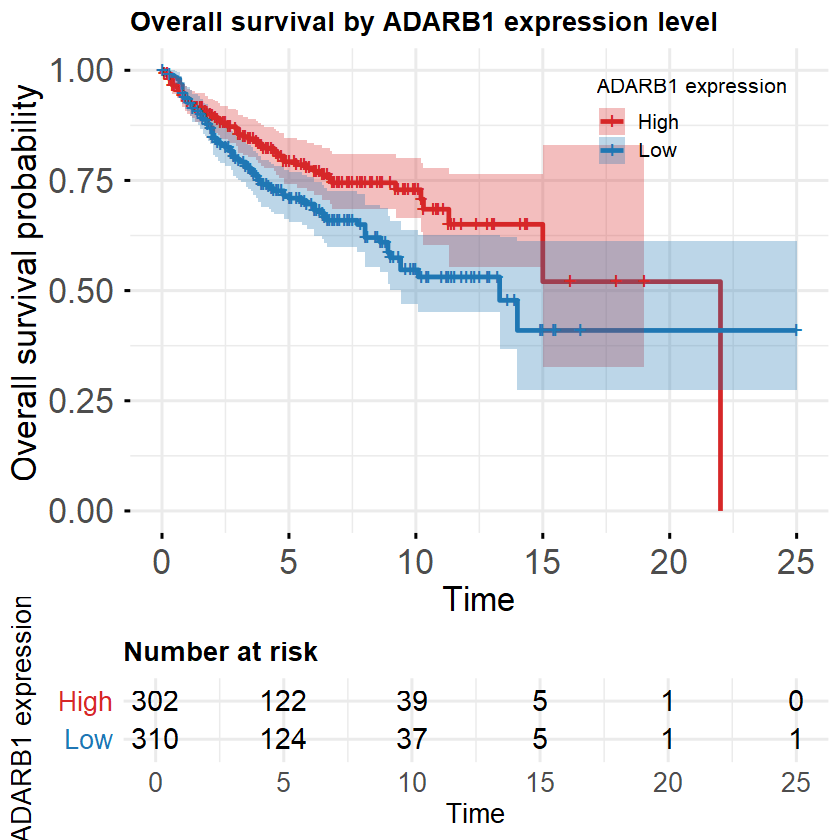

In [8]:
library(survival)
library(survminer)
library(dplyr)

# Median split on ADARB1
df_km <- df %>%
  mutate(ADARB1_group = ifelse(ADARB1 > median(ADARB1, na.rm = TRUE), "High", "Low"))

# Fit the KM survival curve
fit <- survfit(Surv(time, event) ~ ADARB1_group, data = df_km)

# ---- Extract the raw log-rank p-value ----
diff <- survdiff(Surv(time, event) ~ ADARB1_group, data = df_km)
raw_p <- pchisq(diff$chisq, length(diff$n) - 1, lower.tail = FALSE)
cat("Raw log-rank p-value:", raw_p, "\n")

# ---- Apply Bonferroni correction ----
# n_tests = however many comparisons you're correcting across
# e.g., 3 if you're testing ADARB1, ADARB1B1, ADARB1B2 as a family
n_tests <- 3
adj_p <- min(raw_p * n_tests, 1)
cat("Bonferroni-adjusted p-value:", adj_p, "\n")

# Format for display
p_label <- ifelse(adj_p < 0.001,
                   "Bonferroni-adj. p < 0.001",
                   paste0("Bonferroni-adj. p = ", formatC(adj_p, digits = 3, format = "f")))

# ---- Plot, using pval = FALSE and injecting your own label instead ----
p <- ggsurvplot(
  fit, data = df_km,
  pval = FALSE,                        # turn off automatic (uncorrected) p-value
  conf.int = TRUE,
  risk.table = TRUE,
  risk.table.height = 0.25,
  risk.table.fontsize = 6,
  risk.table.title = "Number at risk",
  palette = c("High" = "#d62728", "Low" = "#1f77b4"),
  legend.title = "ADARB1 expression",
  legend.labs = c("High", "Low"),
  legend = c(0.8, 0.85),
  xlab = "Time",
  ylab = "Overall survival probability",
  title = "Overall survival by ADARB1 expression level",
  font.main = c(16, "bold"),
  font.x = c(20, "plain"),
  font.y = c(20, "plain"),
  font.tickslab = c(20, "plain"),
  font.legend = c(12, "plain"),
  ggtheme = theme_minimal(base_size = 14) +
    theme(
      axis.text = element_text(size = 20),
      axis.title = element_text(size = 14),
      plot.title = element_text(size = 16, face = "bold"),
      legend.text = element_text(size = 16),
      legend.title = element_text(size = 16)
    )
)

# Manually add the corrected p-value as an annotation
# p$plot <- p$plot +
#   annotate("text", x = Inf, y = Inf, label = p_label,
#            hjust = 1.05, vjust = 1.5, size = 5.5) +
#   labs(caption = paste0("N = ", nrow(df_km), ", Events = ", sum(df_km$event),
#                           " (High n=", sum(df_km$ADARB1_group == "High"),
#                           ", Low n=", sum(df_km$ADARB1_group == "Low"),
#                           "); raw log-rank p = ", formatC(raw_p, digits = 3, format = "f"))) +
#   theme(plot.caption = element_text(size = 14, hjust = 0))

p$table <- p$table +
  theme(
    axis.text = element_text(size = 16),
    axis.title = element_text(size = 16),
    plot.title = element_text(size = 16)
  )

print(p)

Raw log-rank p-value: 0.2515055 
Bonferroni-adjusted p-value: 0.7545166 


Ignoring unknown labels:
• colour : "ADARB2 expression"
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's fill values."


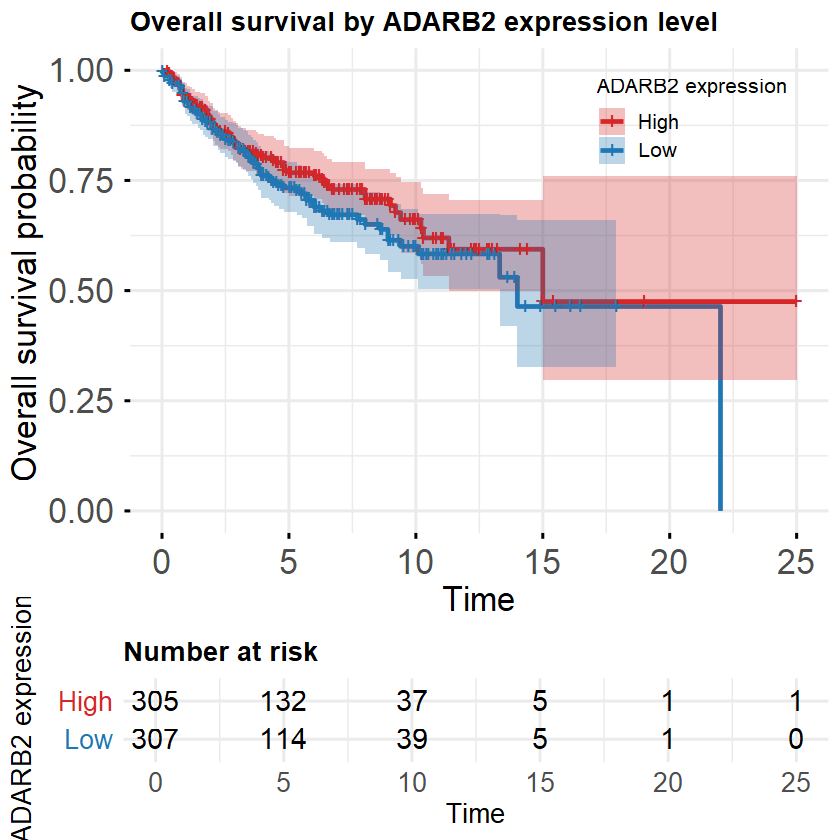

In [9]:
library(survival)
library(survminer)
library(dplyr)

# Median split on ADARB2
df_km <- df %>%
  mutate(ADARB2_group = ifelse(ADARB2 > median(ADARB2, na.rm = TRUE), "High", "Low"))

# Fit the KM survival curve
fit <- survfit(Surv(time, event) ~ ADARB2_group, data = df_km)

# ---- Extract the raw log-rank p-value ----
diff <- survdiff(Surv(time, event) ~ ADARB2_group, data = df_km)
raw_p <- pchisq(diff$chisq, length(diff$n) - 1, lower.tail = FALSE)
cat("Raw log-rank p-value:", raw_p, "\n")

# ---- Apply Bonferroni correction ----
# n_tests = however many comparisons you're correcting across
# e.g., 3 if you're testing ADARB2, ADARB2B1, ADARB2B2 as a family
n_tests <- 3
adj_p <- min(raw_p * n_tests, 1)
cat("Bonferroni-adjusted p-value:", adj_p, "\n")

# Format for display
p_label <- ifelse(adj_p < 0.001,
                   "Bonferroni-adj. p < 0.001",
                   paste0("Bonferroni-adj. p = ", formatC(adj_p, digits = 3, format = "f")))

# ---- Plot, using pval = FALSE and injecting your own label instead ----
p <- ggsurvplot(
  fit, data = df_km,
  pval = FALSE,                        # turn off automatic (uncorrected) p-value
  conf.int = TRUE,
  risk.table = TRUE,
  risk.table.height = 0.25,
  risk.table.fontsize = 6,
  risk.table.title = "Number at risk",
  palette = c("High" = "#d62728", "Low" = "#1f77b4"),
  legend.title = "ADARB2 expression",
  legend.labs = c("High", "Low"),
  legend = c(0.8, 0.85),
  xlab = "Time",
  ylab = "Overall survival probability",
  title = "Overall survival by ADARB2 expression level",
  font.main = c(16, "bold"),
  font.x = c(20, "plain"),
  font.y = c(20, "plain"),
  font.tickslab = c(20, "plain"),
  font.legend = c(12, "plain"),
  ggtheme = theme_minimal(base_size = 14) +
    theme(
      axis.text = element_text(size = 20),
      axis.title = element_text(size = 14),
      plot.title = element_text(size = 16, face = "bold"),
      legend.text = element_text(size = 16),
      legend.title = element_text(size = 16)
    )
)

# Manually add the corrected p-value as an annotation
# p$plot <- p$plot +
#   annotate("text", x = Inf, y = Inf, label = p_label,
#            hjust = 1.05, vjust = 1.5, size = 5.5) +
#   labs(caption = paste0("N = ", nrow(df_km), ", Events = ", sum(df_km$event),
#                           " (High n=", sum(df_km$ADARB2_group == "High"),
#                           ", Low n=", sum(df_km$ADARB2_group == "Low"),
#                           "); raw log-rank p = ", formatC(raw_p, digits = 3, format = "f"))) +
#   theme(plot.caption = element_text(size = 14, hjust = 0))

p$table <- p$table +
  theme(
    axis.text = element_text(size = 16),
    axis.title = element_text(size = 16),
    plot.title = element_text(size = 16)
  )

print(p)

In [ ]:
coxph(Surv(time, event) ~ ADAR + age + gender, data = subset(full, subgroup == "group3"))

Call:
coxph(formula = Surv(time, event) ~ ADAR + age + gender, data = subset(full, 
    subgroup == "group3"))

              coef  exp(coef)   se(coef)      z     p
ADAR     0.0003816  1.0003816  0.0009548  0.400 0.689
age     -0.0228392  0.9774196  0.0228309 -1.000 0.317
genderm  0.3208360  1.3782795  0.3506098  0.915 0.360

Likelihood ratio test=2.15  on 3 df, p=0.5421
n= 110, number of events= 46 

Warning message:
"package 'patchwork' was built under R version 4.4.3"
Warning message:
"`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead."
`height` was translated to `width`.


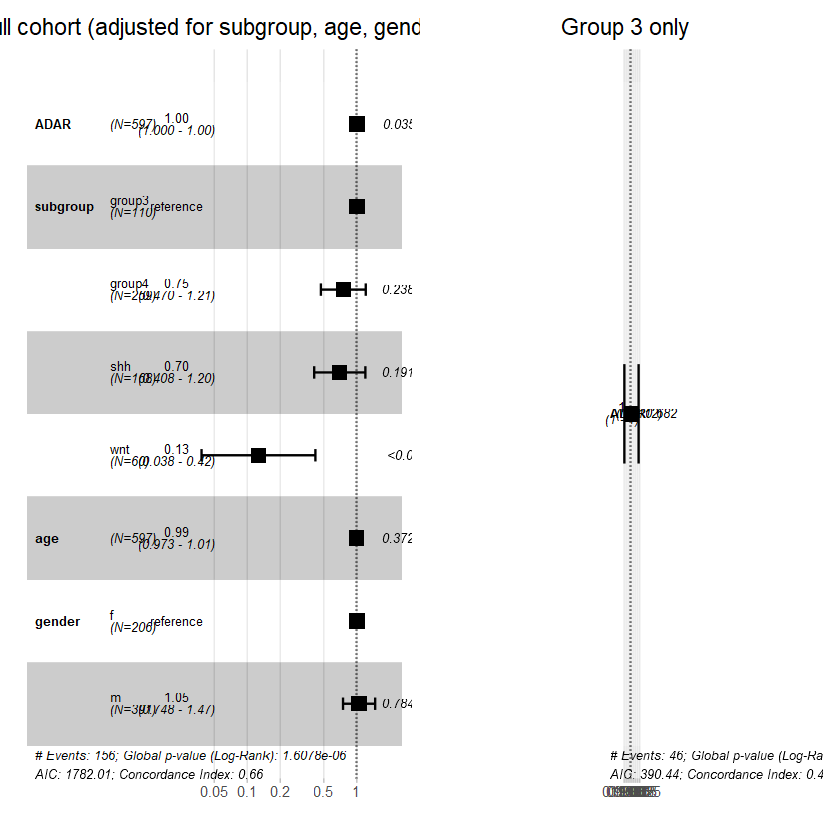

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>."


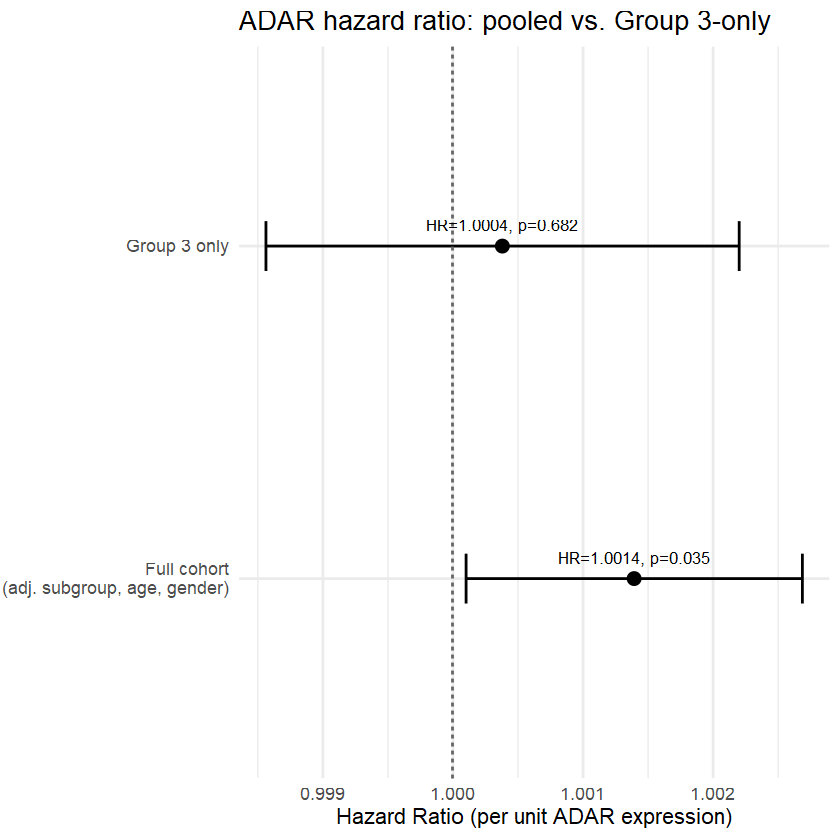

Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's fill values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's fill values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's fill values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual

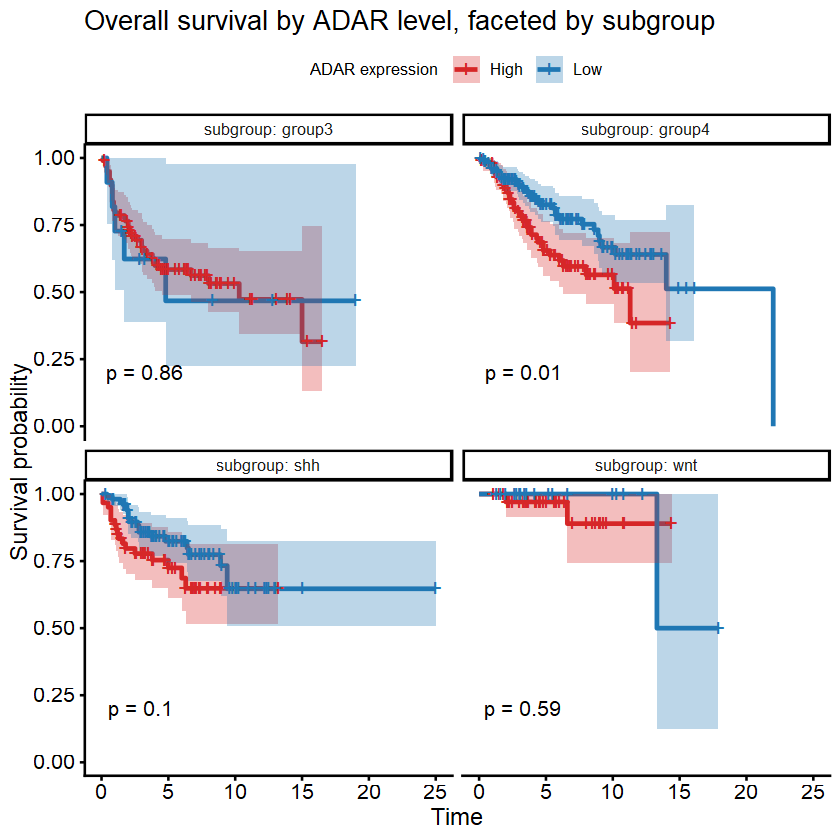

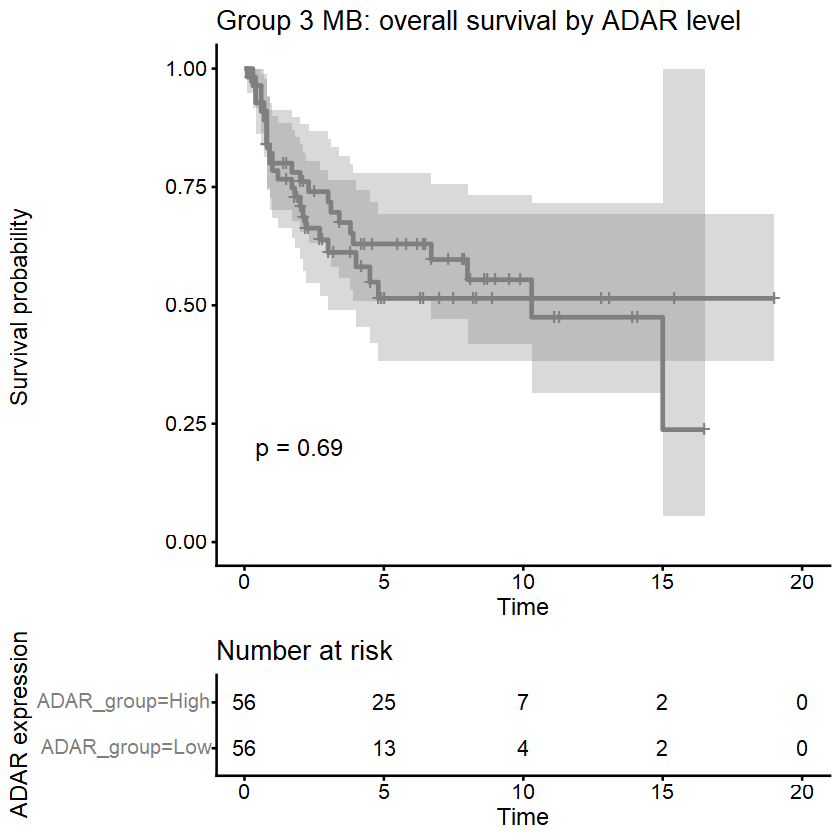

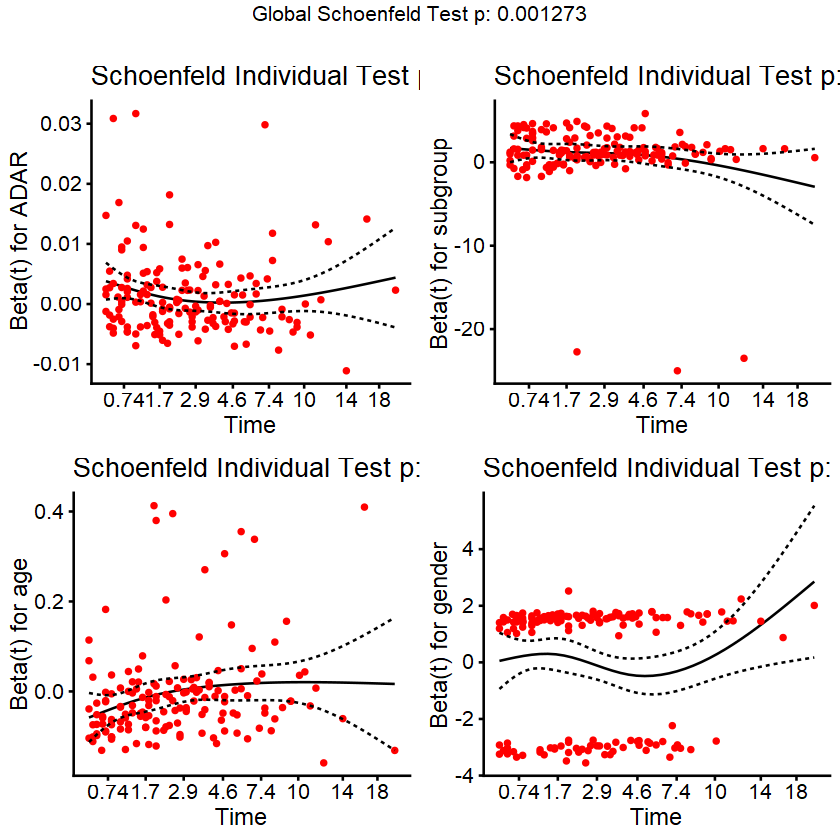

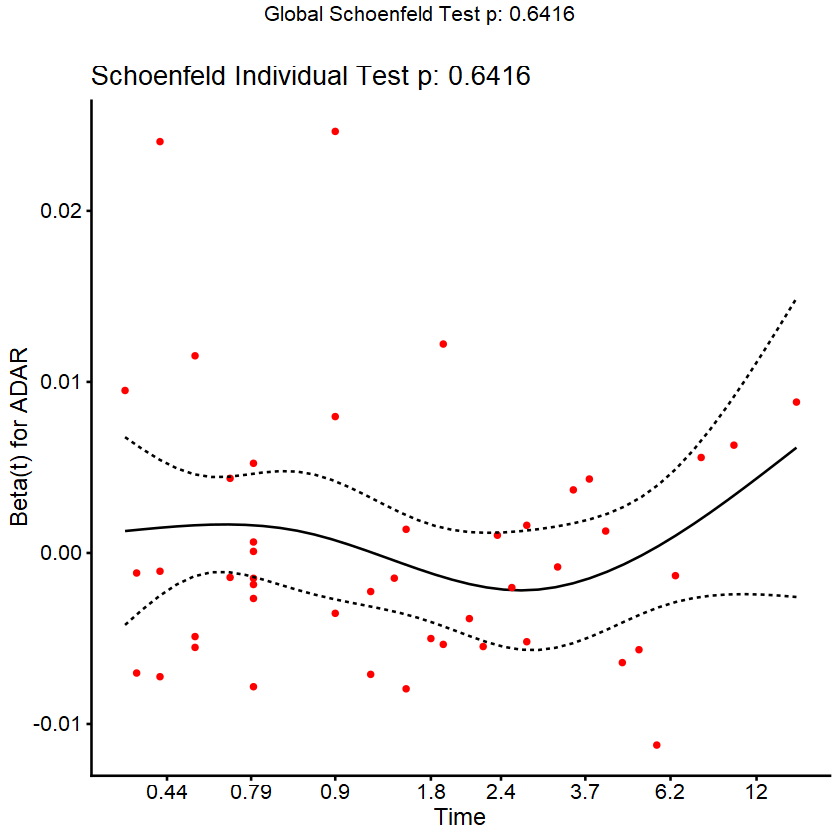

In [ ]:
library(survminer)
library(survival)
library(ggplot2)
library(patchwork)

# ---- 1. Forest plot: pooled model (fit_full) ----
p1 <- ggforest(fit_full, data = full, main = "Full cohort (adjusted for subgroup, age, gender)")

# ---- 2. Forest plot: Group3-only model (fit_g3) ----
p2 <- ggforest(fit_g3, data = g3, main = "Group 3 only")

# View side by side
p1 | p2
# ggsave("forest_full_vs_group3.pdf", p1 | p2, width = 12, height = 5)


# ---- 3. Custom side-by-side ADAR-only forest plot (cleaner for the manuscript figure) ----
# Pull ADAR estimate + CI from each model
adar_full <- summary(fit_full)$coefficients["ADAR", ]
adar_full_ci <- summary(fit_full)$conf.int["ADAR", ]
adar_g3 <- summary(fit_g3)$coefficients["ADAR", ]
adar_g3_ci <- summary(fit_g3)$conf.int["ADAR", ]

forest_df <- data.frame(
  model = c("Full cohort\n(adj. subgroup, age, gender)", "Group 3 only"),
  HR    = c(adar_full_ci["exp(coef)"], adar_g3_ci["exp(coef)"]),
  lower = c(adar_full_ci["lower .95"], adar_g3_ci["lower .95"]),
  upper = c(adar_full_ci["upper .95"], adar_g3_ci["upper .95"]),
  p     = c(adar_full["Pr(>|z|)"], adar_g3["Pr(>|z|)"])
)

ggplot(forest_df, aes(x = HR, y = model)) +
  geom_point(size = 3) +
  geom_errorbarh(aes(xmin = lower, xmax = upper), height = 0.15) +
  geom_vline(xintercept = 1, linetype = "dashed", color = "grey40") +
  geom_text(aes(label = sprintf("HR=%.4f, p=%.3f", HR, p)), vjust = -1.2, size = 3.5) +
  labs(title = "ADAR hazard ratio: pooled vs. Group 3-only",
       x = "Hazard Ratio (per unit ADAR expression)", y = NULL) +
  theme_minimal(base_size = 13)


# ---- 4. KM curves, full cohort, ADAR median split, faceted by subgroup ----
full_km <- full %>%
  mutate(ADAR_group = ifelse(ADAR > median(ADAR, na.rm = TRUE), "High", "Low"))

fit_km_full <- survfit(Surv(time, event) ~ ADAR_group, data = full_km)

ggsurvplot_facet(
  fit_km_full, data = full_km, facet.by = "subgroup",
  pval = TRUE, conf.int = TRUE,
  palette = c("High" = "#d62728", "Low" = "#1f77b4"),
  legend.title = "ADAR expression",
  title = "Overall survival by ADAR level, faceted by subgroup"
)


# ---- 5. KM curve, Group 3 only, ADAR median split ----
g3_km <- g3 %>%
  mutate(ADAR_group = ifelse(ADAR > median(ADAR, na.rm = TRUE), "High", "Low"))

fit_km_g3 <- survfit(Surv(time, event) ~ ADAR_group, data = g3_km)

ggsurvplot(
  fit_km_g3, data = g3_km,
  pval = TRUE, conf.int = TRUE, risk.table = TRUE,
  palette = c("High" = "#d62728", "Low" = "#1f77b4"),
  legend.title = "ADAR expression",
  title = "Group 3 MB: overall survival by ADAR level"
)


# ---- 6. Schoenfeld residuals (PH assumption diagnostic) ----
zph_full <- cox.zph(fit_full)
ggcoxzph(zph_full)   # one panel per covariate, including ADAR

zph_g3 <- cox.zph(fit_g3)
ggcoxzph(zph_g3)